# Phase 2 — What does a late delivery cost?

**Question.** When an Olist order arrives after the date the customer was promised, how much does that
change (a) the review the customer leaves and (b) whether they buy again within 180 days?

**Why it matters.** Phase 4 has to trade off a shorter, more attractive promise against a higher chance of
missing it. That trade-off needs a *causal* price on lateness, not a correlation: late orders differ from
on-time ones in distance, product, season and seller, and all of those could move reviews on their own.

**Approach.** Five estimators with progressively weaker modelling assumptions, all conditioning only on
information available at checkout. If they agree, the answer does not hinge on one model.

| Estimator | Idea |
|---|---|
| Naive difference | Late minus on-time mean |
| Regression + controls | OLS with ~150 checkout-time controls, SEs clustered by seller |
| Regression + seller fixed effects | Compares late and on-time orders *from the same seller* |
| Propensity weighting (ATT) | Re-weights on-time orders to look like late ones |
| Doubly robust, cross-fitted (ATT) | Gradient-boosted propensity + outcome models, 5-fold cross-fitting |

Controls never include anything that happens after checkout (shipping time, carrier time): those are
*how* an order becomes late, and controlling for them would erase the effect being measured.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
sys.path.insert(0, str(ROOT / "analysis"))
import causal as C  # noqa: E402

warnings.filterwarnings("ignore", category=FutureWarning)
# Subsets such as same-state orders make customer_state and seller_state dummies collinear; the
# lateness coefficient is still identified, so the statsmodels rank warning is silenced.
from statsmodels.tools.sm_exceptions import SingularMatrixWarning  # noqa: E402

warnings.filterwarnings("ignore", category=SingularMatrixWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
DB = str(ROOT / "warehouse" / "olist.duckdb")
FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, INK, INK2, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False,
})

## 1. Data

Orders come from `marts.fct_orders` (Phase 1): delivered, no timestamp anomalies, purchased by 2018-08-31, and reviewed.

In [2]:
orders = C.load_orders(DB)
summary = pd.DataFrame({
    "orders": [len(orders)],
    "late share": [orders.late.mean()],
    "avg review, late": [orders.loc[orders.late == 1, "review_score"].mean()],
    "avg review, on time": [orders.loc[orders.late == 0, "review_score"].mean()],
    "sellers": [orders.seller_id.nunique()],
})
summary

,orders,late share,"avg review, late","avg review, on time",sellers
0,95637,0.0667,2.2704,4.2906,2950


## 2. Why the raw gap is suspect

Late orders are not a random subset. The table shows standardised mean differences (SMD) between late and
on-time orders on checkout-time characteristics. |SMD| > 0.1 is the usual threshold for meaningful imbalance.

In [3]:
ps = C.propensity_logit(orders)
bal = C.balance_table(orders, ps=ps)
bal.sort_values("smd_before", key=abs, ascending=False)

,variable,smd_before,smd_after
2,same_state,-0.2795,-0.0162
0,log_distance,0.2739,0.0084
4,log_freight,0.1842,-0.0050
10,promised_days,-0.1439,-0.0040
9,multi_seller,-0.1350,-0.0097
3,log_items_value,0.0908,-0.0059
6,log_weight,0.0721,-0.0057
8,n_items,-0.0635,-0.0079
7,log_volume,0.0540,-0.0016
11,max_installments,0.0475,0.0035


Late orders are more often cross-state, travel further, pay more freight and were given *shorter* promises.
Season matters too (not in the table, which shows numeric controls only): the late share ranges from about 1%
to 19% by purchase month. Distance, product and season could all lower reviews on their own, so the naive
gap could be biased.

## 3. Effect of lateness on the review

In [4]:
rev = C.all_estimates(orders, "review_score")
one = C.all_estimates(orders, "one_star")
rev

,method,estimate,se,ci_low,ci_high,n
0,naive difference,-2.0202,0.0200,-2.0595,-1.9809,95637
1,regression + controls,-1.9841,0.0250,-2.0332,-1.9350,95637
2,regression + seller fixed effects,-1.9417,0.0258,-1.9924,-1.8911,95095
3,propensity weighting (ATT),-1.9990,0.0209,-2.0399,-1.9581,95637
4,"doubly robust, cross-fitted (ATT)",-1.9916,0.0209,-2.0325,-1.9507,95637


In [5]:
one

,method,estimate,se,ci_low,ci_high,n
0,naive difference,0.4716,0.0063,0.4592,0.4839,95637
1,regression + controls,0.4665,0.0070,0.4527,0.4802,95637
2,regression + seller fixed effects,0.4589,0.0070,0.4451,0.4727,95095
3,propensity weighting (ATT),0.4717,0.0064,0.4591,0.4843,95637
4,"doubly robust, cross-fitted (ATT)",0.4712,0.0064,0.4586,0.4838,95637


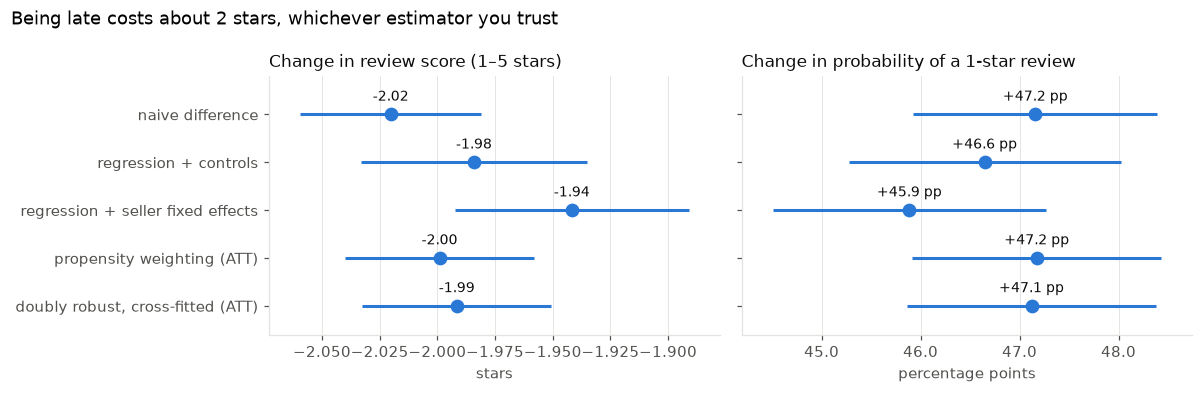

In [6]:
def forest(ax, table, title, xlabel, fmt):
    y = np.arange(len(table))[::-1]
    ax.errorbar(table.estimate, y, xerr=[table.estimate - table.ci_low, table.ci_high - table.estimate],
                fmt="o", color=BLUE, ecolor=BLUE, elinewidth=2, capsize=0, markersize=8)
    for yi, v in zip(y, table.estimate, strict=True):
        ax.annotate(fmt(v), (v, yi), xytext=(0, 9), textcoords="offset points", ha="center", color=INK, fontsize=9)
    ax.set_yticks(y, table.method)
    ax.set_ylim(-0.6, len(table) - 0.2)
    ax.margins(x=0.08)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
forest(axes[0], rev, "Change in review score (1–5 stars)", "stars", lambda v: f"{v:+.2f}")
forest(axes[1], one, "Change in probability of a 1-star review", "percentage points", lambda v: f"{v*100:+.1f} pp")
axes[1].xaxis.set_major_formatter(lambda v, _: f"{v*100:.1f}")
fig.suptitle("Being late costs about 2 stars, whichever estimator you trust", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
fig.savefig(FIG / "02_review_effect_estimators.png", bbox_inches="tight")

All five estimators land between **−1.94 and −2.02 stars** and **+46 to +47 pp** in the chance of a 1-star
review. Adjusting for distance, product, season, payment and even seller identity moves the estimate by
less than 0.1 stars: the review penalty is not an artefact of *which* orders end up late.

### Diagnostics: overlap and balance after weighting

share of late orders with propensity > 0.5: 1.9%
max |SMD| after weighting: 0.016


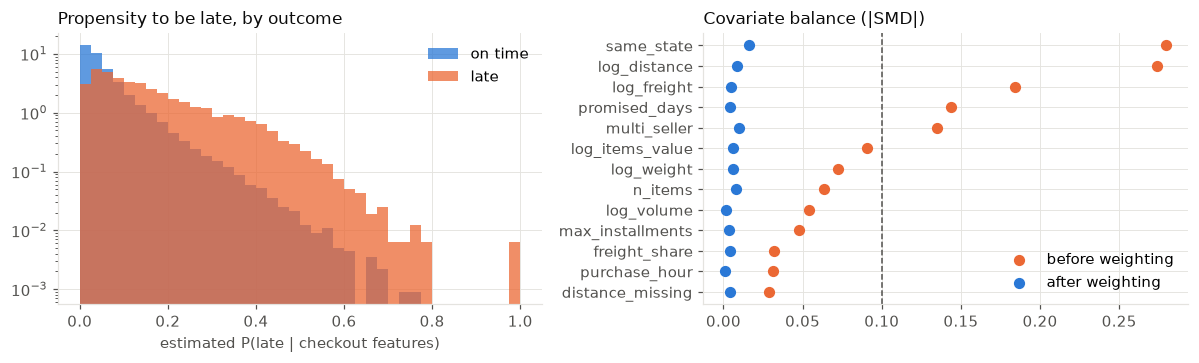

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
bins = np.linspace(0, 1, 41)
axes[0].hist(ps[orders.late == 0], bins=bins, density=True, color=BLUE, alpha=0.75, label="on time")
axes[0].hist(ps[orders.late == 1], bins=bins, density=True, color=ORANGE, alpha=0.75, label="late")
axes[0].set_yscale("log")
axes[0].set_title("Propensity to be late, by outcome", loc="left", fontsize=11)
axes[0].set_xlabel("estimated P(late | checkout features)")
axes[0].legend()

b = bal.sort_values("smd_before", key=abs)
y = np.arange(len(b))
axes[1].scatter(b.smd_before.abs(), y, color=ORANGE, s=40, label="before weighting", zorder=3)
axes[1].scatter(b.smd_after.abs(), y, color=BLUE, s=40, label="after weighting", zorder=3)
axes[1].axvline(0.1, color=INK2, lw=1, ls="--")
axes[1].set_yticks(y, b.variable)
axes[1].set_title("Covariate balance (|SMD|)", loc="left", fontsize=11)
axes[1].legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG / "02_overlap_and_balance.png", bbox_inches="tight")
print(f"share of late orders with propensity > 0.5: {(ps[orders.late == 1] > 0.5).mean():.1%}")
print(f"max |SMD| after weighting: {bal.smd_after.abs().max():.3f}")

Lateness is hard to predict from checkout information alone (fewer than 2% of late orders have an estimated
propensity above 0.5), so on-time orders with very similar profiles exist for virtually every late order.
Weighting brings every numeric control well below the 0.1 SMD threshold.

## 4. Dose-response: it is the *missed promise* that hurts

Adjusted review by how early or late the order arrived, relative to arriving 1–7 days early
(same controls as the regression above).

In [8]:
dr = C.dose_response(orders, "review_score")
dr

,bucket,effect,ci_low,ci_high,n
0,1. 15+ days early,0.3255,0.2948,0.3562,34670
1,2. 8-14 days early,0.1745,0.1484,0.2006,36102
2,3. 1-7 days early,0.0000,0.0000,0.0000,17207
3,4. on the day,-0.1619,-0.2324,-0.0913,1279
4,5. 1-3 days late,-0.8479,-0.9222,-0.7737,1851
5,6. 4-7 days late,-2.0181,-2.0940,-1.9422,1747
6,7. 8-14 days late,-2.4217,-2.4915,-2.3518,1446
7,8. 15+ days late,-2.3381,-2.4130,-2.2632,1335


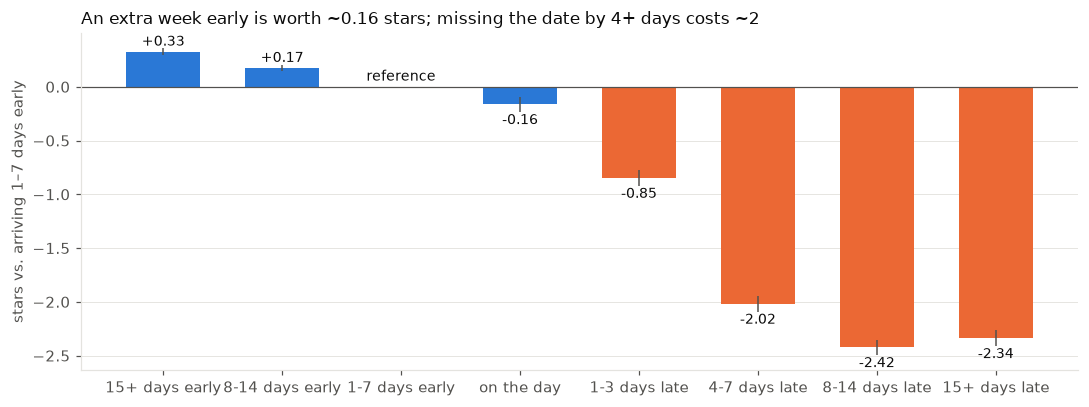

In [9]:
labels = [b.split(". ", 1)[1] for b in dr.bucket]
colors = [BLUE if "early" in b or "on the day" in b else ORANGE for b in dr.bucket]
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(dr))
ax.bar(x, dr.effect, color=colors, width=0.62)
ax.errorbar(x, dr.effect, yerr=[dr.effect - dr.ci_low, dr.ci_high - dr.effect], fmt="none", ecolor=INK2, elinewidth=1)
for xi, v in zip(x, dr.effect, strict=True):
    label = "reference" if v == 0 else f"{v:+.2f}"
    ax.annotate(label, (xi, v), xytext=(0, -13 if v < 0 else 4), textcoords="offset points",
                ha="center", color=INK, fontsize=9)
ax.axhline(0, color=INK2, lw=0.8)
ax.set_xticks(x, labels)
ax.set_ylabel("stars vs. arriving 1–7 days early")
ax.set_title("An extra week early is worth ~0.16 stars; missing the date by 4+ days costs ~2",
             loc="left", fontsize=11)
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIG / "02_dose_response.png", bbox_inches="tight")

The curve is sharply asymmetric. Each extra week of arriving early is worth roughly **+0.16 stars**.
Arriving on the promised day already costs 0.16, 1–3 days late costs 0.85, and 4+ days late costs **2.0–2.4
stars**, after which it plateaus. Earliness is rewarded a little; a missed promise is punished an order of
magnitude more. That asymmetry is the core economics of promise-setting, and Phase 4 prices it directly.

### Mechanism: customers review the wait, not the product

Olist sends its review request around the promised date. For late orders that means the customer often
reviews **before** the parcel arrives.

In [10]:
late = orders[orders.late == 1]
mech = (late.assign(reviewed=np.where(late.review_before_delivery, "before delivery", "after delivery"))
            .groupby("reviewed").agg(orders=("order_id", "size"), avg_days_late=("days_late", "mean"),
                                    avg_review=("review_score", "mean"), one_star=("one_star", "mean")))
mech["share"] = mech.orders / mech.orders.sum()
mech

,orders,avg_days_late,avg_review,one_star,share
reviewed,,,,,
after delivery,1629,1.8748,3.5261,0.1872,0.2554
before delivery,4750,13.4857,1.8398,0.6579,0.7446


About three quarters of late orders are reviewed while the customer is still waiting, and those reviews
average 1.8 stars against 3.5 for late orders reviewed after arrival. This comparison is descriptive, not
causal: orders reviewed before delivery are also the much *later* ones (13.5 vs 1.9 days late on average). But it suggests part of the penalty is
about *when* the survey goes out. Holding the survey until delivery is a cheap lever, separate from actually
delivering faster, and a natural candidate for the Phase 5 experiment.

## 5. Effect of lateness on coming back

One row per first-time customer with a full 180-day follow-up window. Treatment: any order in their first
purchase session arrived late. Outcome: a second purchase session within 180 days. Split checkouts
(several orders placed the same day) count as one session, so they are not mistaken for loyalty (Phase 1).

In [11]:
cust = C.load_customers(DB)
rep = C.all_estimates(cust, "repeat", include_fe=False)
base = cust.loc[cust.late == 0, "repeat"].mean()
rep["relative_change"] = rep.estimate / base
print(f"customers: {len(cust):,}   late first purchase: {cust.late.mean():.1%}   repeat rate (on time): {base:.2%}")
rep

customers: 56,342   late first purchase: 7.0%   repeat rate (on time): 2.03%


,method,estimate,se,ci_low,ci_high,n,relative_change
0,naive difference,-0.0047,0.0021,-0.0087,-0.0006,56342,-0.2292
1,regression + controls,-0.0034,0.0020,-0.0073,0.0005,56342,-0.1671
2,propensity weighting (ATT),-0.0032,0.0022,-0.0075,0.0011,56342,-0.1574
3,"doubly robust, cross-fitted (ATT)",-0.0030,0.0022,-0.0073,0.0013,56342,-0.1469


In [12]:
aipw = rep.iloc[-1]
rr = (base + aipw.estimate) / base
n1, n0 = int(cust.late.sum()), int((cust.late == 0).sum())
se_design = np.sqrt(base * (1 - base) * (1 / n1 + 1 / n0))
mde = 2.8 * se_design  # 80% power, two-sided 5%
print(f"risk ratio (doubly robust): {rr:.2f}  -> E-value {C.e_value(rr):.2f}")
print(f"minimum detectable effect at 80% power: {mde*100:.2f} pp ({mde/base:.0%} of the base rate)")

risk ratio (doubly robust): 0.85  -> E-value 1.62
minimum detectable effect at 80% power: 0.65 pp (32% of the base rate)


The point estimates say a late first order lowers the chance of coming back by roughly **0.3 pp, about 15% of
the 2% base rate** — but the confidence intervals include zero once checkout features are controlled. That
is a power problem, not evidence of no effect: with ~4,000 late first-time customers and a 2% base rate, this
dataset can only reliably detect a drop of about a third. The E-value of 1.6 means an unmeasured confounder
associated with both lateness and retention by a risk ratio of 1.6 could explain the estimate away. That is
not a high bar, so the retention effect should be treated as *plausible but unproven*.

That is exactly the gap a controlled experiment fills, and Phase 5 sizes one.

## 6. Robustness

In [13]:
rows = []
def add(label, df, y, t="late"):
    e = C.ols(df, y, t)
    rows.append({"check": label, "outcome": y, "estimate": e.estimate, "ci_low": e.ci[0], "ci_high": e.ci[1], "n": e.n})

add("baseline", orders, "review_score")
add("drop spike months (Nov-17, Feb/Mar-18)", orders[~orders.purchase_month.isin(C.SPIKE_MONTHS)], "review_score")
add("single-seller, single-item orders only", orders[(orders.n_sellers == 1) & (orders.n_items == 1)], "review_score")
add("treatment = 4+ days late (vs on time)",
    orders[(orders.days_late >= 4) | (orders.late == 0)], "review_score")
add("same-state orders only", orders[orders.same_state == 1], "review_score")
cells_o = orders.assign(cell=orders.purchase_month + "|" + orders.customer_state)
e = C.ols_seller_fe(cells_o, "review_score", fe="cell")
rows.append({"check": "month x customer-state fixed effects", "outcome": "review_score", "estimate": e.estimate,
             "ci_low": e.ci[0], "ci_high": e.ci[1], "n": e.n})
add("baseline", cust, "repeat")
add("drop spike months", cust[~cust.purchase_month.isin(C.SPIKE_MONTHS)], "repeat")
cust4 = cust[(cust.first_session_max_days_late >= 4) | (cust.late == 0)]
add("treatment = 4+ days late", cust4, "repeat")
cells_c = cust.assign(cell=cust.purchase_month + "|" + cust.customer_state)
e = C.ols_seller_fe(cells_c, "repeat", fe="cell")
rows.append({"check": "month x customer-state fixed effects", "outcome": "repeat", "estimate": e.estimate,
             "ci_low": e.ci[0], "ci_high": e.ci[1], "n": e.n})
robust = pd.DataFrame(rows)
robust

,check,outcome,estimate,ci_low,ci_high,n
0,baseline,review_score,-1.9841,-2.0332,-1.9350,95637
1,"drop spike months (Nov-17, Feb/Mar-18)",review_score,-1.8504,-1.9114,-1.7894,74945
2,"single-seller, single-item orders only",review_score,-2.0334,-2.0837,-1.9831,86139
3,treatment = 4+ days late (vs on time),review_score,-2.4004,-2.4500,-2.3509,93786
4,same-state orders only,review_score,-1.7187,-1.8128,-1.6245,34417
5,month x customer-state fixed effects,review_score,-1.9580,-2.0591,-1.8570,95622
6,baseline,repeat,-0.0034,-0.0073,0.0005,56342
7,drop spike months,repeat,-0.0031,-0.0091,0.0030,42081
8,treatment = 4+ days late,repeat,-0.0043,-0.0089,0.0003,55300
9,month x customer-state fixed effects,repeat,-0.0027,-0.0066,0.0012,56323


In [14]:
placebo = C.placebo_shuffle(orders, "review_score", n=20)
print(f"placebo (lateness shuffled within month x state), 20 draws: mean {placebo.mean():+.3f}, "
      f"range [{placebo.min():+.3f}, {placebo.max():+.3f}]   vs real effect {rev.estimate.iloc[1]:+.2f}")

placebo (lateness shuffled within month x state), 20 draws: mean +0.001, range [-0.031, +0.054]   vs real effect -1.98


The review effect survives every cut, between −1.7 and −2.4 stars. It is somewhat smaller for same-state
orders (−1.7) and larger when only 4+ days late counts as late (−2.4), consistent with the dose-response
curve. Absorbing every purchase-month × customer-state cell, which removes regional congestion in a given
month, leaves it at −1.96.

**Placebo.** When lateness is shuffled at random within month × state cells, the estimated "effect" is
indistinguishable from zero, so the result is not manufactured by the controls or the seasonality.

The retention estimate stays negative in every specification (−0.27 to −0.43 pp), but no interval excludes zero.

## 7. What this means for the business

* **A missed promise costs about 2 stars and turns ~47% of those customers into 1-star reviewers.** This is
  stable across five estimators and every robustness check.
* **Early delivery is worth little to the customer** (≈ +0.16 stars per extra week). Promises can be
  shortened, *as long as they are still kept*.
* **The penalty arrives fast**: 1–3 days late already costs almost a star, and three quarters of late orders
  are reviewed before they arrive.
* **Retention probably suffers too (≈ −15%), but this data cannot prove it**; a test would.

**Inputs carried forward**
* Phase 3 (prediction): the outcome that matters is P(delivered after promise), so the model must be
  calibrated in the upper tail of delivery time, not just accurate on average.
* Phase 4 (trade-off): cost of lateness ≈ 2.0 stars per late order (doubly robust ATT); value of
  extra slack ≈ 0.16 stars per week early (dose-response).
* Phase 5 (experiment): retention MDE from observational data is ~0.65 pp; the experiment must be sized to
  detect smaller effects than that.

In [15]:
out = pd.concat([rev.assign(outcome="review_score"), one.assign(outcome="one_star"), rep.assign(outcome="repeat_180d")])
out.to_csv(ROOT / "docs" / "phase2_estimates.csv", index=False)
out[["outcome", "method", "estimate", "ci_low", "ci_high", "n"]]

,outcome,method,estimate,ci_low,ci_high,n
0,review_score,naive difference,-2.0202,-2.0595,-1.9809,95637
1,review_score,regression + controls,-1.9841,-2.0332,-1.9350,95637
2,review_score,regression + seller fixed effects,-1.9417,-1.9924,-1.8911,95095
3,review_score,propensity weighting (ATT),-1.9990,-2.0399,-1.9581,95637
4,review_score,"doubly robust, cross-fitted (ATT)",-1.9916,-2.0325,-1.9507,95637
0,one_star,naive difference,0.4716,0.4592,0.4839,95637
1,one_star,regression + controls,0.4665,0.4527,0.4802,95637
2,one_star,regression + seller fixed effects,0.4589,0.4451,0.4727,95095
3,one_star,propensity weighting (ATT),0.4717,0.4591,0.4843,95637
4,one_star,"doubly robust, cross-fitted (ATT)",0.4712,0.4586,0.4838,95637
